# 01 — Adaptive local contrast Policy Preview

Apply this version's offline policy to a fixed random sample of calibration originals to inspect routing, per-image cost and before/after pixels. Nothing is exported, trained or tuned here.

**Inputs:** v3.yaml (this folder), the shared split table and original calibration images.

**Outputs:** In-memory tables and figures only.

**Prerequisites:** Original BDD sources under the shared data_root. No upstream notebook is executed.

**Outline**

- [1. Configuration](#section-1)
- [2. Policy on Calibration Samples](#section-2)
- [3. Policy Summary](#section-3)

<a id="section-1"></a>

## 1. Configuration

Change SAMPLES/SHOW freely; policy parameters live only in the version YAML.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from vehicle_detection.common import project_root, read_image, require_paths
from vehicle_detection.experiment_data import load_experiment, shared_splits
from vehicle_detection.preprocess import apply_recipe

ROOT = project_root()
os.chdir(ROOT)  # Run All behaves the same from any kernel working directory.
EXPERIMENT = "v3"
require_paths(
    config=ROOT / f"notebooks/experiments/{EXPERIMENT}/{EXPERIMENT}.yaml",
    shared=ROOT / "configs/data.yaml",
)
config = load_experiment(ROOT, EXPERIMENT)

SAMPLES = 64
SHOW = 4
shared, rows = shared_splits(ROOT)
data_root = ROOT / shared["data_root"]
require_paths(data_root=data_root)

<a id="section-2"></a>

## 2. Policy on Calibration Samples

Features are measured on the original pixels; only the routed operator changes the image.

,images,ms,brightness,contrast
applied,,,,
,35,3.045521,0.347117,0.237980
local_contrast,29,18.291620,0.099815,0.106931


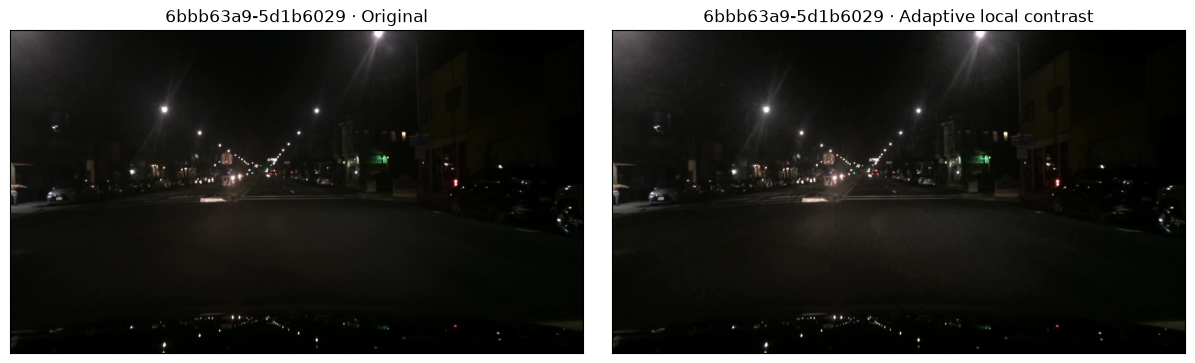

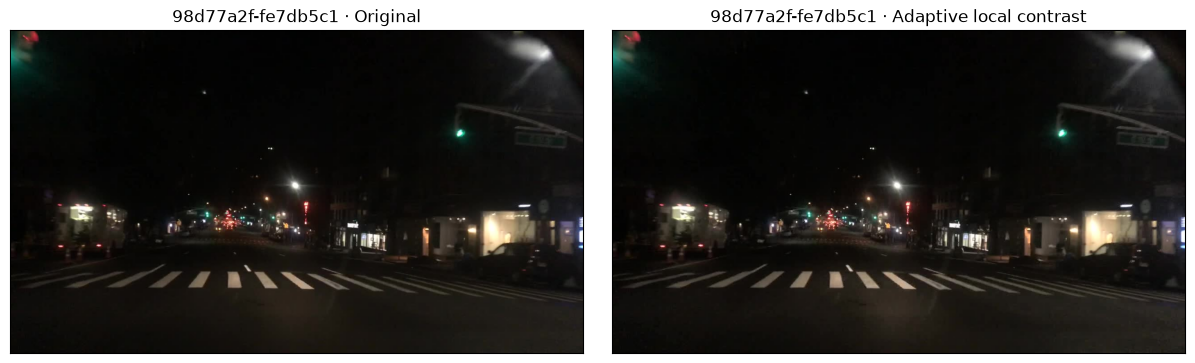

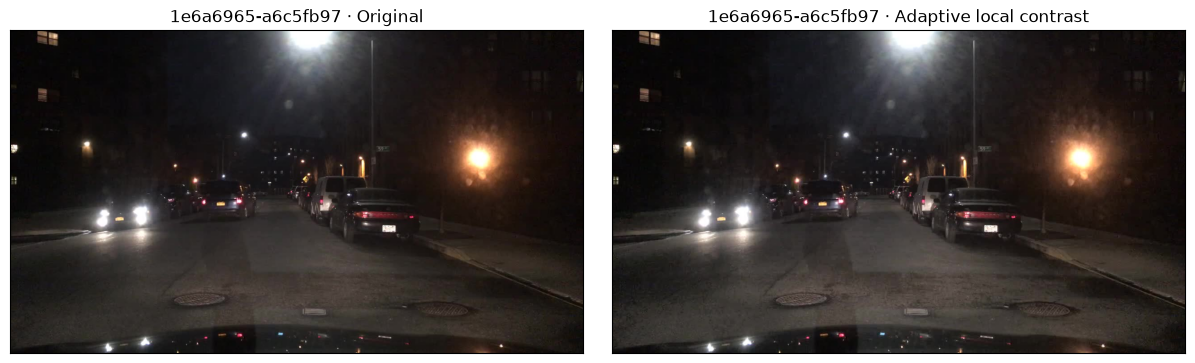

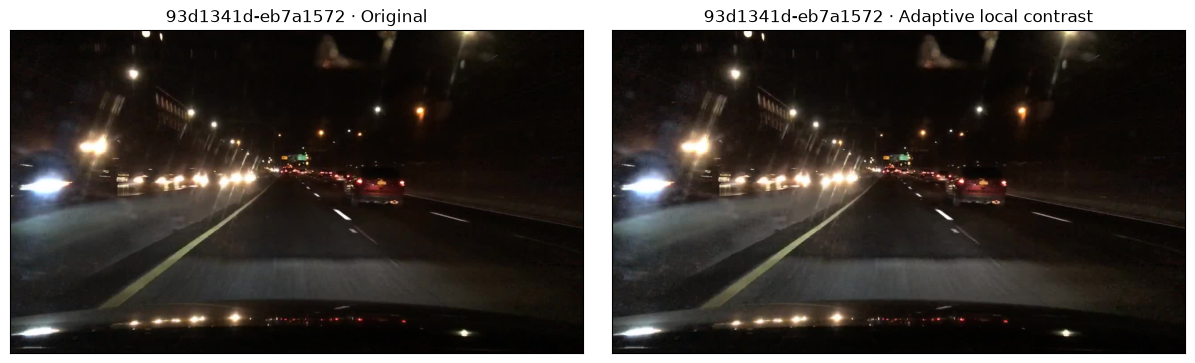

In [2]:
calibration = [r for r in rows if r["role"] == "calibration"]
picked = np.random.default_rng(config["seed"]).choice(len(calibration), SAMPLES, replace=False)
records, pairs = [], []
for index in picked:
    row = calibration[index]
    image = read_image(data_root / row["source_path"])
    start = time.perf_counter()
    output, applied, scores = apply_recipe(image, config["variant"], config["recipes"])
    elapsed = (time.perf_counter() - start) * 1000
    records.append(
        {"id": row["id"], "applied": "+".join(a["name"] for a in applied), "ms": elapsed, **scores}
    )
    if applied and len(pairs) < SHOW:
        pairs.append((row["id"], image, output))
preview = pd.DataFrame(records)
display(
    preview.groupby("applied", dropna=False).agg(
        images=("id", "size"),
        ms=("ms", "mean"),
        brightness=("brightness", "mean"),
        contrast=("contrast", "mean"),
    )
)
for sample_id, before, after in pairs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
    for ax, image, label in zip(axes, (before, after), ("Original", config["name"]), strict=True):
        ax.imshow(image[:, :, ::-1])
        ax.set(title=f"{sample_id} · {label}", xticks=[], yticks=[])
    plt.show()

<a id="section-3"></a>

## 3. Policy Summary

In [3]:
print("Variant:", config["variant"], "| Recipes:", config["recipes"])
print(f"Applied to {(preview.applied != '').mean():.1%} of {len(preview)} calibration samples")
print("Export happens only in 02_train_prepare; final-test pixels stay sealed.")

Variant: adaptive_local_contrast | Recipes: {'adaptive_local_contrast': {'contrast_below': 0.2, 'brightness_above': 0.04, 'brightness_below': 0.8, 'noise_max': 0.01, 'black_below': 0.3, 'white_below': 0.1}, 'local_contrast': {'clip_limit': 1.5, 'grid_size': 8, 'gain': 0.5, 'max_offset': 12}}
Applied to 45.3% of 64 calibration samples
Export happens only in 02_train_prepare; final-test pixels stay sealed.


## Historical experiment lineage — v3

This notebook retains the existing full-finetune preprocessing preview **and its saved outputs**, and restores the historical Issue #47 experimental protocols as non-executable documentation. In particular, failed Gamma/Sharpen and adaptive_local pilot gates remain failed; post-hoc S20 training does not retroactively constitute independent confirmation. The two Raw-resolution studies are separate controls, **not v3 improvements**. This notebook does not rerun any model or open final-test data.

Current preparation, training, native evaluation and cross-policy checks remain in `02_train_prepare`, `03_train`, `04_eval` and `../compare.ipynb`. Historical code depends on modules removed by PR #55, so the archived cells below do not execute.

### Embedded historical results (readable without Git or external JSON)

Snapshot: `948e1d3fd5d7f1f745121fb1ad5063076a682884` (pre-PR #55). The 15 historical registry JSON files are absent from the current tree; the summaries below were transcribed from that pinned snapshot and its named reports. Percentages are AP50:95 unless stated; differences are percentage points (pp). No historical inference/training was rerun for this restoration. The final holdout remains sealed.

**Naming boundary:** historical “frozen v2” means Issue #6’s `issue6-policy-v2` Gamma-or-Skip; it is not today’s local-shadow `v2`. Historical frozen-backbone experiments are separate from current full fine-tuning.

#### v3-gamma-detail — Gamma/Sharpen routed pilot

Four arms on 1,027 calibration-exploration images / 649 groups gave AP50:95: Skip 16.904200%, exposure 16.909368%, detail 16.906175%, complete route 16.910513%. The route gained only +0.006313 points (conditional 95% interval [-0.095116, +0.115024]), below +0.2. Exposure/truck lost 3.322365 points and dark/truck 1.786283; exposure, detail and intersection lacked required five-class support. Cost passed (routed mean/p95 2.266/3.083 ms), but accuracy, uncertainty, regression and support gates failed. `advance=False`, `policy_frozen=False`, `v3_trained=False`; no candidate promoted or confirmation consumed.

Provenance: [docs/issue47/summary.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue47/summary.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE47_RESULTS.md). JSON SHA256: `1407752147818ce370294e9a1da99ff3f1ff19ce32b671a55354ecabd589bbc2`.

#### v3-diagnosis — Descriptive failure diagnosis

On the consumed 1,027-image pilot population, motorcycle had 31 GT / 1 TP / 8 FP / 30 FN and bicycle 86 GT / 14 TP / 2 FP / 72 FN at confidence .25 / IoU .50. Of images containing these classes, 28/29 and 55/59 were bright; 28/29 and 54/59 were skipped by the old route. These associations motivate new mechanisms but cannot locate individual missed boxes or establish causes. A separately declared Raw-only 640-to-960 diagnostic gained +2.372712 AP points with conditional 95% interval [+1.360202, +3.961617], passing its exploratory gates; that is resolution sensitivity, not v3 policy confirmation or trained S20 evidence.

Provenance: [docs/issue47-discovery/diagnosis.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue47-discovery/diagnosis.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE47_DISCOVERY_RESULTS.md). JSON SHA256: `787707ce3050b500cd37b0479926e3fa8ca58d0f2af502e4489e19730785f33c`.

#### raw-short — Raw-only short resolution training

Two five-epoch arms used the same 2,048 S20 training images / 1,244 groups and consumed 1,027 calibration-exploration images. Fixed last-checkpoint AP50:95 for train/infer 640/640, 640/960, 960/640, 960/960 was 20.219447%, 22.842672%, 19.252958%, 23.756023%. Incremental training-resolution gain at inference 960 was +0.913351 points, but its conditional 95% interval [-0.081883, +1.778887] crossed zero and dark-bus lost 7.766145 points. Stop without promotion: uncertainty and supported-regression gates failed, `s20_promoted=False`, `policy_selected=False`. The original attempt hit a validator API error; this explicitly declared repeat used the same seed/population and is not independent replication. No enhancer was applied.

Provenance: [docs/issue47-resolution-training-repeat/result.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue47-resolution-training-repeat/result.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE47_TRAINING_RESULTS.md). JSON SHA256: `4d0d33279d2d15b9c7370bbc8f506d83aae8b12ac2a97b322327a2a8fce4a8af`.

#### raw-s20 — Raw-only full-S20 resolution training

Both Raw-only models trained all 9,781 S20 images for 20 epochs; checkpoint selection reused 13,975 Raw development images at fixed actual 640. Train/infer 640/640, 640/960, 960/640, 960/960 AP50:95 was 20.612379%, 22.397992%, 20.311641%, 24.568446%. Incremental training gain at inference 960 was +2.170454 points (conditional 95% interval [+1.773, +2.620]). Overall decision remained `inconclusive`: dark-bus AP increased while fixed-confidence TP/FN worsened; no policy selected or independent confirmation. One seed and reused-development/model-selection uncertainty limit the result. This control changes resolution, not v3 preprocessing.

Provenance: [docs/issue47-s20-resolution-20e/result.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue47-s20-resolution-20e/result.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE51_RESULTS.md). JSON SHA256: `88b39147543e1880da3a9b41c4b9c4d4e2de0490b6eb59f96bb9ddc12a28a27a`.

#### v3-local — Prospective adaptive-local 960 pilot

Using the fixed trained Raw S20/960 checkpoint on 1,479 fresh calibration-exploration images / 926 groups, AP50:95 was Raw 26.011103%, always-local 26.034995%, adaptive-local 26.158582%. Adaptive gained +0.147479 points (conditional 95% interval [-0.050963, +0.415904]); two-wheeler mean gain +0.275893 missed +0.5 and dark-bus lost 1.616524 points. Primary improvement, interval, two-wheeler and regression gates failed; no freezing, training or promotion. Apply/Skip was 584/895; route separation +0.943667 points and cost 5.811/11.913 ms passed their gates but cannot override failures. Plan/implementation were committed before acquisition at `55d5b04`; the now-consumed exploration pool is not future confirmation.

Provenance: [docs/issue47-v3-960/result.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue47-v3-960/result.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE47_V3_960_RESULTS.md). JSON SHA256: `03bf7e7d0dd30a99cb1958ac62a9f0c551f696e3d7a873d626a15b298d66f8d4`.

#### v3-posthoc — Post-hoc adaptive S20/960 training

A separately requested single-seed run trained all 9,781 S20 images for 20 epochs, FP32 AdamW, frozen backbone 11, with shared Raw development selection (13,975 images). At inference 960, AP50:95 for Raw/Raw, Raw/Adaptive, Adaptive/Raw, Adaptive/Adaptive was 24.568446%, 24.537852%, 24.491937%, 24.525520%. Training on Adaptive at fixed Adaptive inputs changed AP by -0.012332 points; joint change was -0.042925. Motorcycle/bicycle training contrasts lost 1.426130/0.799729 points. Completed post-hoc exploration, not a passed prospective gate or independent confirmation: no bootstrap significance claim or policy release. Plan committed at `a94c0c8` before preparation; the failed pilot remains failed.

Provenance: [docs/issue47-posthoc-adaptive-960/result.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue47-posthoc-adaptive-960/result.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE47_POSTHOC_RESULTS.md). JSON SHA256: `05984f14f636d8142ff5aaa8f116974021b5c70b84db82c533b16b2e25e30408`.



## A. Study registry and saved evidence

Execute the next cell to review experiment scope and provenance. To inspect a saved historical report without triggering any inference/training, call `inspect_saved_study("v3-local")` (or another study ID). It reads the pinned Git snapshot when available; missing history is reported explicitly.

In [ ]:
# Research evidence viewer: read-only, no training or inference
import json
import subprocess

import pandas as pd
from IPython.display import display

HISTORICAL_COMMIT = "948e1d3fd5d7f1f745121fb1ad5063076a682884"
RESEARCH_ROOT = ROOT  # Reuse the preview configuration and its prerequisite checks.
STUDIES = [
    {
        "id": "v3-gamma-detail",
        "provenance": "historical pilot",
        "population": "Issue47 Gamma/Sharpen/combined/Skip",
        "evidence": "docs/issue47/summary.json",
        "boundary": "No candidate promoted",
    },
    {
        "id": "v3-diagnosis",
        "provenance": "historical diagnosis",
        "population": "Issue47 class/cohort/error analysis",
        "evidence": "docs/issue47-discovery/diagnosis.json",
        "boundary": "Associations do not prove causes",
    },
    {
        "id": "raw-short",
        "provenance": "Raw-only control",
        "population": "640/960 short training matrix",
        "evidence": "docs/issue47-resolution-training-repeat/result.json",
        "boundary": "Not a v3 policy effect",
    },
    {
        "id": "raw-s20",
        "provenance": "Raw-only control",
        "population": "S20 resolution 20-epoch matrix",
        "evidence": "docs/issue47-s20-resolution-20e/result.json",
        "boundary": "Not a v3 policy effect",
    },
    {
        "id": "v3-local",
        "provenance": "historical prospective pilot",
        "population": "1479 fresh IDs, Raw/always/adaptive",
        "evidence": "docs/issue47-v3-960/result.json",
        "boundary": "Original prospective failure gates apply",
    },
    {
        "id": "v3-posthoc",
        "provenance": "historical post-hoc",
        "population": "Adaptive 960 S20 + four-cell eval",
        "evidence": "docs/issue47-posthoc-adaptive-960/result.json",
        "boundary": "Cannot reclassify a failed pilot",
    },
    {
        "id": "v3-current",
        "provenance": "current full-finetune",
        "population": "S20; YOLO26n full-finetune",
        "evidence": "notebooks/experiments/v3/04_eval.ipynb",
        "boundary": "Use current 02–04 lifecycle",
    },
]

display(
    pd.DataFrame(STUDIES).rename(
        columns={
            "id": "Study",
            "provenance": "Source",
            "population": "Population / design",
            "evidence": "Evidence file",
            "boundary": "Interpretation",
        }
    )
)


def archived_evidence(path):
    """Use the pinned historical commit, falling back to a labelled local copy."""
    try:
        proc = subprocess.run(
            ["git", "-C", str(RESEARCH_ROOT), "show", f"{HISTORICAL_COMMIT}:{path}"],
            capture_output=True,
            check=False,
            timeout=20,
        )
        if proc.returncode == 0:
            return proc.stdout, f"commit {HISTORICAL_COMMIT[:12]}"
    except (OSError, subprocess.TimeoutExpired):
        pass
    local = RESEARCH_ROOT / path
    if local.is_file():
        return local.read_bytes(), "local file: verify revision"
    return None, "not available in local checkout"


def inspect_saved_study(study_id):
    """Display saved records without new acquisition, model runs or made-up metrics."""
    s = next((item for item in STUDIES if item["id"] == study_id), None)
    if s is None:
        raise ValueError(f"Unknown study: {study_id}")
    print("Study:", s["id"], "|", s["population"])
    print("Boundary:", s["boundary"])
    path = s["evidence"]
    if path.endswith(".ipynb"):
        print("Active lifecycle notebook:", path)
        return
    raw, origin = archived_evidence(path)
    print("Evidence:", path, "|", origin)
    if raw is None:
        print("Missing saved evidence is NOT a zero metric or failed study.")
        return
    if path.endswith(".json"):
        report = json.loads(raw.decode("utf-8"))
        if isinstance(report, dict):
            print("Saved fields:", list(report))
        display(report)
    elif path.endswith(".csv"):
        from io import BytesIO

        display(pd.read_csv(BytesIO(raw)).head(30))
    else:
        print(raw.decode("utf-8", errors="replace")[:12000])


# Run manually: inspect_saved_study("v3-local")

## B. Full historical research notebooks (archived source)

The original 01_experiments notebook and five Issue #47 studies are transcribed below: pilots, method diagnosis, Raw-only resolution controls, prospective adaptive_local test and post-hoc training. The source cells are shown as fenced Python and **not executed**, because the refactor removed several historical modules and research evidence directories. No conclusions have been regenerated.

### 1. 01_experiments.ipynb

**Historical experiment protocol (source only).** [Original notebook before PR #55](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/notebooks/experiments/v3/01_experiments.ipynb). All procedure/code cells are preserved as text. Old source modules may no longer exist on main; nothing below executes them, accesses datasets or creates new metrics.

**Original cell 1 — narrative**

#### 01 — Adaptive local contrast with the trained Raw S20/960 detector

One prospective local-structure hypothesis, with Raw and always-on controls. Historical Gamma/Sharpen evidence remains byte-exact in [the research notebook](../../research/issue47/04_gamma_sharpen_pilot.ipynb).

**Inputs:** Committed docs/ISSUE47_V3_960_PLAN.md, exact fresh calibration membership, and compact version-local evidence. Acquisition alone needs original allowed pixels and the PR #52 Raw960 checkpoint.

**Outputs:** Hash-verified displays by default; one opted-in three-arm acquisition under runs/issue47-v3-960 and docs/issue47-v3-960.

**Prerequisites:** Project notebook kernel and committed declaration. No upstream notebook runs. Acquisition requires the frozen code/membership in Git, CUDA and pinned Ultralytics.

**Original cell 2 — narrative**

##### 1. Configuration

The plan excludes all recorded earlier calibration exposure, including Issue #6/#11. All 1,479 remaining exploration images are fixed before pixels; no threshold fitting, sample expansion or runner-up promotion. Default execution opens no models, original pixels or local runs.

**Original cell 3 — archived Python (not executed)**

```python
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from vehicle_detection.common import require_paths
from vehicle_detection.v3_adaptive import run

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
require_paths(plan=ROOT / "docs/ISSUE47_V3_960_PLAN.md")
ALLOW_PILOT = False
```

**Original cell 4 — narrative**

##### 2. Paired Native Detection and Cost

Only `adaptive_local` may advance. The same bounded achromatic CLAHE difference is applied unconditionally in `always_local` to test whether the pixel gate predicts detection benefit. This is detection-evaluated preprocessing, not a reproduction of jointly learned enhancement. All arms share original five-class labels and JPEG95; native nominal 960 uses rectangular pad .5.

The pretrained historical pilot and PR #52 development numbers are different populations and are not compared here.

**Original cell 5 — archived Python (not executed)**

```python
result = run(ROOT, allow_inference=ALLOW_PILOT)
if "metrics" in result:
    display(
        pd.DataFrame(
            {a: v["all"] | {"classes": None, "counts": None} for a, v in result["metrics"].items()}
        ).T.drop(columns=["classes", "counts"])
    )
    display(pd.DataFrame(result["runtime"]).T)
    display(result["routing"])
    arms = list(result["metrics"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(arms, [100 * result["metrics"][a]["all"]["mAP50_95"] for a in arms])
    axes[0].set(
        ylabel="Native five-class AP50:95 (%)", title="Same trained detector / same fresh IDs"
    )
    classes = list(result["metrics"]["raw"]["all"]["classes"])
    delta = [
        100
        * (
            result["metrics"]["adaptive_local"]["all"]["classes"][s]["AP50_95"]
            - result["metrics"]["raw"]["all"]["classes"][s]["AP50_95"]
        )
        for s in classes
    ]
    axes[1].barh(classes, delta)
    axes[1].axvline(0, color="black", linewidth=0.6)
    axes[1].set(xlabel="Adaptive minus Raw AP points", title="Class effects")
    fig.tight_layout()
    plt.show()
else:
    display(result)
```

**Original cell 6 — narrative**

##### 3. Support, Errors and Uncertainty

All/dark/bright intervals use 1,000 paired original-source-group draws with no missing-class imputation/redraw. Full draws are losslessly compressed beside the summary. Rare-class and supported cohort regressions cannot be hidden by aggregate AP. Fixed-confidence .25 / IoU .50 counts are separate from AP and native F1-selected operating points. Small-two-wheeler cohort AP retains every GT in those images; it is not AP-small.

CPU mean/p95 use eight threads, three repeats and rotated arm order including features, excluding decode/JPEG/inference equally. Native GPU stage means and batch p95 are separate measurements.

**Original cell 7 — archived Python (not executed)**

```python
if "metrics" in result:
    for cohort in ("all", "dark", "bright", "apply", "skip", "low_sharpness", "small_two_wheeler"):
        print(cohort)
        display({a: v[cohort] for a, v in result["metrics"].items()})
    display(result["intervals"])
    display(result["measurements"])
    print("Full draw archives and deterministic class-count examples: docs/issue47-v3-960")
```

**Original cell 8 — narrative**

##### 4. Lifecycle Summary

A qualifying exploration authorizes only freezing the one candidate and the prospective confirmation membership. One group-disjoint confirmation must pass the unchanged gates before any S20 preparation/training. Failure stops this hypothesis; it does not establish that all adaptive methods or aligned fine-tuning fail.

Continue independently through 02_train_prepare → 03_train → 04_eval for the verified lifecycle status. Cross-version comparisons belong exclusively in ../compare.ipynb. No S100 or v4 is created; final-test pixels remain sealed.

**Original cell 9 — archived Python (not executed)**

```python
display(result.get("decision", result))
if "decision" in result:
    print(
        "Eligible for one frozen confirmation"
        if result["decision"]["advance"]
        else "Stop: no confirmed policy; no v3 data, training or development metrics."
    )
    display(
        {
            k: result[k]
            for k in (
                "policy_frozen",
                "v3_trained",
                "confirmation_accessed",
                "development_accessed",
                "final_test_accessed",
            )
        }
    )
```



### 2. 04_gamma_sharpen_pilot.ipynb

**Historical experiment protocol (source only).** [Original notebook before PR #55](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/notebooks/research/issue47/04_gamma_sharpen_pilot.ipynb). All procedure/code cells are preserved as text. Old source modules may no longer exist on main; nothing below executes them, accesses datasets or creates new metrics.

**Original cell 1 — narrative**

#### 01 — Adaptive Exposure/Detail Exploration

Test two fixed pixel mechanisms and their ordered composition on unconsumed natural calibration groups. The historical Adaptive V3 router is not reused.

**Inputs:** Committed docs/ISSUE47_PLAN.md and compact docs/issue47 evidence; original calibration sources and pinned weights only for an explicitly authorized new pilot.

**Outputs:** Verified evidence displays by default; one opted-in acquisition writes runs/issue47/pilot and docs/issue47. No training or upstream notebook execution.

**Prerequisites:** Project kernel and committed evidence. New inference additionally requires the study environment, original BDD sources and pinned weights; the declaration and implementation must already be committed.

**Original cell 2 — narrative**

##### 1. Configuration

Default execution reads compact committed evidence only. ALLOW_PILOT=True authorizes exactly the declared four-arm matrix on a fresh output root; any existing or incomplete attempt blocks re-execution. Read the plan before changing this flag.

**Original cell 3 — archived Python (not executed)**

```python
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from vehicle_detection.common import read_json, require_paths
from vehicle_detection.v3_pilot import run

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
require_paths(plan=ROOT / "docs/ISSUE47_PLAN.md")
ALLOW_PILOT = False
```

**Original cell 4 — narrative**

##### 2. Native Paired Exploration

Four arms share original IDs/GT and JPEG95: Skip, exposure component, detail component, and the full routed treatment. These are pretrained natural calibration results, not S20 detector results. Subgroup AP covers represented classes only; missing rare-class support blocks advancement.

**Original cell 5 — archived Python (not executed)**

```python
result = run(ROOT, allow_inference=ALLOW_PILOT)
display(pd.DataFrame(result["native"]).T)
display(pd.DataFrame(result["runtime"]).T)
display(result["routing"])
for subgroup in (
    "exposure",
    "detail",
    "both",
    "skip",
    "dark",
    "bright",
    "blurred",
    "small_two_wheeler",
):
    print(subgroup)
    display({arm: records[subgroup] for arm, records in result["metrics"].items()})
display(Image(filename=str(ROOT / "docs/issue47/pilot.png")))
```

**Original cell 6 — narrative**

##### 3. Errors and Uncertainty

Fixed-confidence .25 / IoU .50 TP/FP counts are illustrative and never per-image AP. The 100-draw exploratory interval resamples original source groups, records missing classes, and has no multiplicity correction. The saved examples use TP loss then FP rise, with ID tie-breaking.

**Original cell 7 — archived Python (not executed)**

```python
report = ROOT / "docs/issue47"
uncertainty = read_json(report / "uncertainty.json")
display(
    {
        key: uncertainty[key]
        for key in (
            "recovery",
            "recovery_ci_low",
            "recovery_ci_high",
            "valid_draws",
            "invalid_draws",
            "estimand",
        )
    }
)
errors = read_json(report / "errors.json")
for subgroup in ("dark", "blurred", "small_two_wheeler"):
    print(subgroup)
    display({i: errors["counts"][i] for i in errors["examples"][subgroup]})
display(Image(filename=str(report / "errors.png")))
```

**Original cell 8 — narrative**

##### 4. Exploration Summary

Apply the preregistered gates once. Failed or unsupported routes stop the complete candidate; components cannot become post hoc replacements. Confirmation, preparation, training and development evaluation require a defensible frozen policy and separate saved prerequisites. Cross-version presentation belongs exclusively in ../compare.ipynb.

**Original cell 9 — archived Python (not executed)**

```python
display(result["decision"])
print("No policy is promoted by this notebook. See docs/ISSUE47_RESULTS.md for the decision.")
print("Confirmation, development and final pixels stay sealed during this pilot.")
```



### 3. 01_method_discovery.ipynb

**Historical experiment protocol (source only).** [Original notebook before PR #55](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/notebooks/research/issue47/01_method_discovery.ipynb). All procedure/code cells are preserved as text. Old source modules may no longer exist on main; nothing below executes them, accesses datasets or creates new metrics.

**Original cell 1 — narrative**

#### Issue #47 — Method Discovery After the Negative Pilot

Preserve PR #48 and investigate a different mechanism before choosing another preprocessing candidate.

**Inputs:** Hash-verified committed PR #48 evidence and this study's saved diagnosis/resolution evidence. Explicit acquisition additionally needs original annotation metadata, saved matching caches and verified Skip JPEG95 exports.

**Outputs:** Read-only evidence displays by default; opted-in diagnosis and a single fixed 640/960 native diagnostic under docs/issue47-discovery and runs/issue47-discovery.

**Prerequisites:** Committed discovery plan and saved evidence; study dependencies/pinned weights only for explicitly enabled acquisition. No upstream notebooks execute. No new exploration, confirmation, development or final pixels are read.

**Original cell 2 — narrative**

##### 1. Configuration

Read docs/ISSUE47_DISCOVERY_PLAN.md before opting in. Existing/incomplete acquisition attempts block re-execution. Default execution only reads committed artifacts, without native inference, GT loading or local runs.

**Original cell 3 — archived Python (not executed)**

```python
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from vehicle_detection.common import require_paths
from vehicle_detection.method_discovery import build_diagnosis, read_report, resolution

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
REPORT = ROOT / "docs/issue47-discovery"
require_paths(plan=ROOT / "docs/ISSUE47_DISCOVERY_PLAN.md")
ALLOW_DIAGNOSIS = False
ALLOW_RESOLUTION = False
```

**Original cell 4 — narrative**

##### 2. Saved Failure Diagnosis

Class TP/FP/FN uses native confidence .25 / IoU .50 matches and original GT counts. Size distributions describe all GT, not individual missed boxes. Cohorts retain all GT in each image; their AP is not AP-small. Metadata and image quality describe associations, not causes.

**Original cell 5 — archived Python (not executed)**

```python
diagnosis = build_diagnosis(ROOT) if ALLOW_DIAGNOSIS else read_report(ROOT)
print(diagnosis["population"])
display(pd.DataFrame(diagnosis["size_support"]).T)
for group in (
    "all",
    "dark",
    "bright",
    "low_contrast",
    "higher_noise",
    "small_two_wheeler",
    "route_skip",
):
    print(group)
    display(pd.DataFrame(diagnosis["cohorts"]["skip"][group]["counts"]).T)
print(diagnosis["limit"])
print("Full per-class/cohort AP and original scene attributes remain in diagnosis.json.")
```

**Original cell 6 — narrative**

##### 3. Ranked Mechanisms and Research Decision

The table records the premeasurement literature review and distinguishing controls for the completed 640/960 diagnostic. The current next priority is resolution-aware fine-tuning, described in section 5; task-aligned photometric training remains secondary. The committed measurement plan is unchanged. Spatial correction and one possible SCI comparator are deferred; no new enhancement framework/checkpoint is installed.

**Original cell 7 — archived Python (not executed)**

```python
display(
    pd.DataFrame(
        [
            {
                "Rank": 1,
                "Direction": "Native 640 versus 960 diagnostic",
                "Mechanism": "Retain more object detail",
                "Evidence": "Poor bright two-wheeler coverage; some small targets",
                "Control": "Same JPEG95/GT/model, only imgsz changes",
                "Budget": "2 native evaluations / 2,054 image passes",
                "Falsification": "Primary, two-wheeler, uncertainty, regression or cost gates fail",
            },
            {
                "Rank": 2,
                "Direction": "Task-aligned photometric training",
                "Mechanism": "Learn exposure robustness rather than only brighten inputs",
                "Evidence": "Enhancement did not rescue mostly skipped two-wheelers",
                "Control": "Future paired native short training; augmentation only",
                "Budget": "Not authorized in this round",
                "Falsification": "No supported held-out gain or clean-data harm",
            },
            {
                "Rank": 3,
                "Direction": "Constrained luminance/local contrast",
                "Mechanism": "Expose retained shadow structure while protecting highlights",
                "Evidence": "Current global features do not localize correctable target shadows",
                "Control": "Future local versus matched global correction",
                "Budget": "Deferred; no filter grid",
                "Falsification": "No detection benefit or amplified FP/noise",
            },
            {
                "Rank": 4,
                "Direction": "One possible SCI comparator",
                "Mechanism": "Learn spatial illumination",
                "Evidence": "External face/segmentation results are not BDD vehicle evidence",
                "Control": "One prospectively fixed checkpoint versus Skip",
                "Budget": "Deferred; license/checkpoint/CPU cost unresolved",
                "Falsification": "No native detection gain or excessive CPU cost",
            },
        ]
    ).set_index("Rank")
)
```

**Original cell 8 — narrative**

##### 4. Controlled Resolution Diagnostic

Both evaluations use the already-consumed population. This is not an offline preprocessing policy, a cross-version S20 comparison, or independent confirmation. Native per-image mean timings and synchronized batch mean/p95 are reported separately; batch p95 is never called image p95. The original 640 result is checked for reproduction.

**Original cell 9 — archived Python (not executed)**

```python
result = resolution(ROOT, allow_inference=ALLOW_RESOLUTION)
display(pd.DataFrame(result["native"]).T)
display(result["timings"])
display(result["decision"])
interval = result["paired_interval"]
display(
    {
        k: interval[k]
        for k in ("recovery", "recovery_ci_low", "recovery_ci_high", "valid_draws", "invalid_draws")
    }
)
if (REPORT / "discovery.png").exists():
    display(Image(filename=str(REPORT / "discovery.png")))
```

**Original cell 10 — narrative**

##### 5. Research Summary

**Next priority: a separately declared short paired 640/960 fine-tuning diagnostic.** Independently initialize both arms from the same pinned YOLO26n weights with identical train IDs/GT, epochs, seed, freeze and augmentation settings. Evaluate each arm at both 640 and 960 on the same consumed exploration IDs. This 2×2 matrix must test whether training at 960 adds benefit over the 640-trained arm evaluated at 960, rather than just reproduce the existing inference-resolution gain.

Declare the source-group-safe subset, compute budget, rare-class uncertainty and supported cohort/clean-regression stop criteria before running it. Report VRAM, training time and inference latency; disclose any necessary batch-size difference as a confounder. Task-aligned photometric training remains a secondary candidate, with no augmentation change in the resolution test.

Read docs/ISSUE47_DISCOVERY_RESULTS.md for the decision and limitations. This PR preserves the measured results and frozen plan, adds no inference/training, and does not select a preprocessing policy or promote 960 to a v3 S20 result. Issue #47 remains open; full S20 training still requires a justified candidate and independent confirmation.

**Original cell 11 — archived Python (not executed)**

```python
print("Preprocessing policy selected:", result["policy_selected"])
print("Independent confirmation:", result["decision"]["independent_confirmation"])
print("PR #48 and completed v0/v1/v2 artifacts remain unchanged; issue #47 stays open.")
```



### 4. 02_resolution_training.ipynb

**RAW-ONLY resolution control (not a v3 preprocessing effect).** [Original notebook before PR #55](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/notebooks/research/issue47/02_resolution_training.ipynb). All procedure/code cells are preserved as text. Old source modules may no longer exist on main; nothing below executes them, accesses datasets or creates new metrics.

**Original cell 1 — narrative**

#### Issue #47 — Resolution-aware training diagnostic

Two matched short runs test whether training at 960 adds benefit beyond inference resizing. This is not a v3 preprocessing policy or S20/development evidence.

**Inputs:** Committed training declaration and compact saved evidence. Acquisition requires pinned YOLO26n/CUDA, original annotation metadata and existing Raw training / consumed Skip evaluation exports.

**Outputs:** Read-only 2×2 matrix, source-group uncertainty, class/cohort errors, cost and decision; opted-in acquisition writes only new docs/issue47-resolution-training-repeat and runs/issue47-resolution-training-repeat/study artifacts.

**Prerequisites:** Read docs/ISSUE47_TRAINING_PLAN.md. No upstream notebook is executed. Existing/incomplete attempts block re-execution. Confirmation, development and final pixels stay sealed.

This is the explicitly requested fresh repeat after the first attempt's acquisition bug; original artifacts remain preserved. The same seed/population is not independent replication.

**Original cell 2 — narrative**

##### 1. Configuration

Default execution verifies compact committed artifacts without models, annotations, datasets or local runs. Commit the declaration and implementation before enabling acquisition.

Read docs/ISSUE47_TRAINING_REPEAT_PLAN.md for the user-authorized repeat budget and software correction.

**Original cell 3 — archived Python (not executed)**

```python
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from vehicle_detection.common import require_paths
from vehicle_detection.resolution_training import run

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
require_paths(plan=ROOT / "docs/ISSUE47_TRAINING_REPEAT_PLAN.md")
ALLOW_TRAINING = False
```

**Original cell 4 — narrative**

##### 2. Fixed paired acquisition or saved evidence

Whole-group S20 prefix; five epochs at each training size, identical batch 16/settings, independently initialized COCO checkpoint. Report fixed last.pt. Only the consumed 1,027 exploration images are evaluated. This short study does not select checkpoints on development or establish convergence.

**Original cell 5 — archived Python (not executed)**

```python
result = run(ROOT, allow_training=ALLOW_TRAINING)
print(result["population"])
rows = []
for key, metrics in result["metrics"].items():
    train_size, inference_size = key.split("/")
    rows.append(
        {
            "train_size": train_size,
            "inference_size": inference_size,
            "mAP50:95 (%)": 100 * metrics["all"]["mAP50_95"],
            "mAP50 (%)": 100 * metrics["all"]["mAP50"],
        }
    )
display(pd.DataFrame(rows))
display(Image(filename=str(ROOT / "docs/issue47-resolution-training-repeat/training.png")))
```

**Original cell 6 — narrative**

##### 3. Incremental training benefit and uncertainty

Primary contrast: 960-trained versus 640-trained, both evaluated at 960. Bootstrap uses original source groups, 100 fixed paired draws, all-five-class macro and no missing-class imputation. Conditional intervals are exploratory on consumed data. Rare-class uncertainty is reported separately.

**Original cell 7 — archived Python (not executed)**

```python
interval = result["paired_interval"]
print("Primary incremental AP points:", 100 * interval["recovery"])
print(
    "Conditional 95% interval:",
    [100 * interval[k] for k in ("recovery_ci_low", "recovery_ci_high")],
)
print("Valid / excluded draws:", interval["valid_draws"], interval["invalid_draws"])
display(pd.DataFrame(interval["per_class"]))
for cohort in ("all", "dark", "bright", "low_contrast", "low_sharpness", "small_two_wheeler"):
    print(cohort, "— all original GT retained; cohort AP is not AP-small")
    for arm in ("640/960", "960/960"):
        print(arm)
        display(pd.DataFrame(result["metrics"][arm][cohort]["classes"]).T)
        display(pd.DataFrame(result["metrics"][arm][cohort]["counts"]).T)
```

**Original cell 8 — narrative**

##### 4. Cost and illustrative errors

Training wall times and peak allocated VRAM are measured per run. Native inference means and synchronized batch p95 include sequential/setup effects; batch p95 is not image p95 or deployment latency. There is no added offline filter. Examples rank TP change, FP change, then original ID; no individual AP or missed-box attribution is inferred.

**Original cell 9 — archived Python (not executed)**

```python
display(pd.DataFrame(result["training"]).T)
display(pd.DataFrame(result["timings"]).T)
display(pd.DataFrame(result["examples"]))
```

**Original cell 10 — narrative**

##### 5. Summary and next boundary

Preserve every failed prospective gate. A useful signal recommends a later separately declared group-disjoint study; it cannot select an adaptive policy or promote S20. One seed and a short training budget do not establish convergence or generalization. Existing Gamma/Sharpen and 640/960 pretrained evidence remain unchanged. Cross-version S20 results belong only in experiments/compare.ipynb.

**Original cell 11 — archived Python (not executed)**

```python
display(result["decision"])
assert not result["decision"]["policy_selected"]
assert not result["decision"]["s20_promoted"]
assert not result["confirmation_development_final_pixels_accessed"]
print("Issue #47 remains open; no confirmation/development/final inference or full S20 promotion.")
```



### 5. 03_full_resolution_training.ipynb

**RAW-ONLY resolution control (not a v3 preprocessing effect).** [Original notebook before PR #55](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/notebooks/research/issue47/03_full_resolution_training.ipynb). All procedure/code cells are preserved as text. Old source modules may no longer exist on main; nothing below executes them, accesses datasets or creates new metrics.

**Original cell 1 — narrative**

#### Issue #51 — Full S20 resolution training

Two independent 20-epoch YOLO26n arms, one fixed Raw checkpoint-selection procedure, and four development evaluations. This is single-seed development evidence; Issue #47 remains open.

**Inputs:** Finalized `docs/ISSUE47_FULL_TRAINING_PLAN.md` and verified implementation receipt. Acquisition additionally requires the frozen S20/development metadata, existing verified v0 Raw JPEG95 exports, pinned YOLO26n and CUDA.

**Outputs:** New owned `runs/issue47-s20-resolution-20e/` and compact `docs/issue47-s20-resolution-20e/` evidence. No historical artifact is overwritten.

**Prerequisites:** Commit the verified protocol/implementation before explicitly enabling acquisition. No upstream notebook runs. Confirmation and final pixels remain sealed. This implementation has not acquired real data or trained a GPU model.

**Original cell 2 — narrative**

##### 1. Configuration

All acquisition flags default to False. Restart & Run All verifies frozen code/plan and saved compact evidence, or reports not acquired, without loading datasets, annotations, models or local runs. Enable only the stage explicitly intended; stages read saved prerequisites.

**Original cell 3 — archived Python (not executed)**

```python
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from vehicle_detection.common import require_paths
from vehicle_detection.full_resolution_training import (
    PLAN,
    RECEIPT,
    STUDY,
    evaluate,
    prepare,
    read_report,
    train,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
require_paths(protocol=ROOT / PLAN, verification=ROOT / RECEIPT)
ALLOW_PREPARATION = False
ALLOW_TRAINING = False
ALLOW_INFERENCE = False
result = read_report(ROOT)
print(result["status"])
```

**Original cell 4 — narrative**

##### 2. Verify and prepare owned Raw data

Explicit preparation verifies all 9,781 training / 13,975 development IDs, group separation and existing Raw export receipts. It copies data once, checks label/image bytes and geometry, computes fixed development cohorts, and records historical preservation. Existing or partial attempts block preparation. No original source pixels or confirmation/final pixels are needed.

**Original cell 5 — archived Python (not executed)**

```python
if ALLOW_PREPARATION:
    prepare(ROOT, allow_preparation=True)
```

**Original cell 6 — narrative**

##### 3. Two native training arms with fixed-640 selection

Same pinned initialization, seed 2026, batch 16, FP32 AdamW, frozen backbone 11 and disabled augmentations; only training resolution differs. Both train for 20 epochs, sequentially, without automatic recovery or resume.

Selection uses the same Raw development at actual maximum tensor edge 640, native rectangular dataset with pad=0, batch 32, native fitness/best.pt and every-epoch plus terminal validation. Training remains square 640/960. Saved pre-strip checkpoint receipts identify selected epochs, including ties. Native CPU tests verify this behavior before real acquisition.

**Original cell 7 — archived Python (not executed)**

```python
if ALLOW_TRAINING:
    train(ROOT, allow_training=True)
```

**Original cell 8 — narrative**

##### 4. Fixed matrix and saved evidence

Evaluate the same selected checkpoint for each arm at both inference sizes, in fixed order A (640/640), D (960/960), B (640/960), C (960/640). Inference keeps native rectangular pad=.5; record actual shapes. Primary D−B isolates training resolution at inference 960. The 1,000 paired original-source-group draws for all/dark/bright are CPU analysis only, fixed before outcomes.

**Original cell 9 — archived Python (not executed)**

```python
if ALLOW_INFERENCE:
    evaluate(ROOT, allow_inference=True)
result = read_report(ROOT)
if result["status"] == "completed":
    display(
        pd.DataFrame(
            [
                {
                    "train/infer": key,
                    "mAP50:95 (%)": 100 * m["all"]["mAP50_95"],
                    "mAP50 (%)": 100 * m["all"]["mAP50"],
                }
                for key, m in result["metrics"].items()
            ]
        )
    )
    display(Image(filename=str(ROOT / f"docs/{STUDY}/convergence_matrix.png")))
    display({key: 100 * value for key, value in result["contrasts"].items()})
else:
    print(result["status"], "— no completed full-S20 results exist.")
```

**Original cell 10 — narrative**

##### 5. Class support, errors and uncertainty

Report motorcycle/bicycle and dark-bus GT counts, source groups and individual intervals. Sparse support, intervals crossing zero or AP gains with worse fixed-confidence TP/FN cannot become a clean success. Counts use conf≥.25 / IoU .50 from native matches; AP uses conf=.001. Cohort AP retains all GT and is not AP-small. Intervals are conditional on selected models and reused development, without training-seed uncertainty or multiplicity correction.

**Original cell 11 — archived Python (not executed)**

```python
if result["status"] == "completed":
    for key, metrics in result["metrics"].items():
        for cohort in ("all", "dark", "bright", "small_two_wheeler"):
            print(key, cohort)
            display(pd.DataFrame(metrics[cohort]["classes"]).T)
            display(pd.DataFrame(metrics[cohort]["counts"]).T)
    for cohort, interval in result["cohort_intervals"].items():
        print(cohort)
        if interval is not None:
            print(
                "Draws / valid / missing-class:",
                interval["resamples"],
                interval["valid_draws"],
                interval["invalid_draws"],
            )
            display(pd.DataFrame(interval["per_class"]))
    display(pd.DataFrame(result["examples"]))
```

**Original cell 12 — narrative**

##### 6. Convergence, cost and Summary

Inspect all 20 epochs, train/val losses, learning rates, selection peaks and final trends. Do not extend the budget based on curves. The ~3 GPU-hours is a planning ceiling, not measured runtime. Abort limits are 90/150 minutes per arm and 14 GiB allocated VRAM. GPU batch p95 is not per-image p95 or deployment latency. Cross-version S20 comparisons stay in experiments/compare.ipynb.

**Original cell 13 — archived Python (not executed)**

```python
if result["status"] == "completed":
    for size in (640, 960):
        print("Training", size)
        display(pd.read_csv(ROOT / f"docs/{STUDY}/train{size}_results.csv"))
    display(pd.DataFrame(result["training"]).T)
    display(pd.DataFrame(result["timings"]).T)
    display(result["decision"])
    assert not result["confirmation_final_accessed"]
    assert not result["decision"]["policy_selected"]
    assert not result["decision"]["independent_confirmation"]
print("Issue #47 remains open; this study does not release an adaptive policy.")
```



### 6. 05_posthoc_adaptive_training.ipynb

**Historical experiment protocol (source only).** [Original notebook before PR #55](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/notebooks/research/issue47/05_posthoc_adaptive_training.ipynb). All procedure/code cells are preserved as text. Old source modules may no longer exist on main; nothing below executes them, accesses datasets or creates new metrics.

**Original cell 1 — narrative**

#### 05 — Post-hoc Adaptive V3 S20/960 fine-tuning

One explicitly requested exploratory training arm with the unchanged adaptive_local policy. Earlier frozen gate failures remain unchanged; this is not independent confirmation or a policy release.

**Inputs:** The committed post-hoc plan/code, PR #52's saved Raw S20/960 data/checkpoint/metadata and pinned pretrained weights. Original S20/development sources are needed only for opted-in preparation.

**Outputs:** Owned runs/issue47-posthoc-adaptive-960 and compact docs/issue47-posthoc-adaptive-960 evidence. Default execution only inspects saved results.

**Prerequisites:** Project notebook kernel; explicit acquisition additionally requires the frozen implementation, exact baseline prerequisites, original allowed sources and CUDA. No other notebook is executed.

**Original cell 2 — narrative**

##### 1. Configuration

Read docs/ISSUE47_POSTHOC_TRAINING_PLAN.md. All switches default False. The user's latest request separately authorizes this post-hoc experiment despite the prior stop-before-training result. Confirmation and final-test data stay sealed; no threshold or augmentation changes are allowed.

**Original cell 3 — archived Python (not executed)**

```python
from pathlib import Path

from IPython.display import display

from vehicle_detection.common import require_paths
from vehicle_detection.posthoc_training import evaluate, prepare, read_report, train

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
require_paths(plan=ROOT / "docs/ISSUE47_POSTHOC_TRAINING_PLAN.md")
ALLOW_PREPARATION = False
ALLOW_TRAINING = False
ALLOW_INFERENCE = False
```

**Original cell 4 — narrative**

##### 2. Owned Raw and Adaptive Preparation

Verify exactly 9,781 S20 / 13,975 development IDs and original GT/negatives. Adaptive JPEG95 comes from original pixels, never from re-encoded Raw data. Raw reproduction and all label bytes must match PR #52. All model-facing files/caches are owned; source access is limited to these two approved populations.

**Original cell 5 — archived Python (not executed)**

```python
prepared = prepare(ROOT, allow_preparation=ALLOW_PREPARATION)
if prepared is not None:
    display(prepared)
```

**Original cell 6 — narrative**

##### 3. One Independent Native Training Run

Load the original pinned COCO YOLO26n, not Raw best.pt. Train 20 epochs at square960, batch16, seed2026 and all PR #52 settings. Native checkpoint selection uses shared Raw development at actual640 / pad0; every tensor/pass and selected checkpoint is checked. Existing/incomplete attempts cannot be overwritten or resumed.

**Original cell 7 — archived Python (not executed)**

```python
trained = train(ROOT, allow_training=ALLOW_TRAINING)
if trained is not None:
    display(
        {
            "selected_epoch": trained["selected_epoch"],
            "checkpoint_hashes": trained["checkpoint_hashes"],
        }
    )
```

**Original cell 8 — narrative**

##### 4. Fixed Four-cell Development Evaluation

Raw/Raw → Raw/Adaptive → Adaptive/Raw → Adaptive/Adaptive, all at nominal960 / native pad.5, with unchanged checkpoints and original GT. Raw/Raw must reproduce PR #52. No new model choice, calibration/confirmation acquisition or threshold search follows these measurements. Matrix presentation and per-class comparisons belong in experiments/compare.ipynb.

**Original cell 9 — archived Python (not executed)**

```python
evaluated = evaluate(ROOT, allow_inference=ALLOW_INFERENCE)
if evaluated is not None:
    display(
        {
            "status": evaluated["status"],
            "scope": evaluated["scope"],
            "completed_cells": list(evaluated["metrics"]),
        }
    )
```

**Original cell 10 — narrative**

##### 5. Post-hoc Study Summary

Development was already used for selection and is reused here. A point gain cannot retrospectively pass the original policy gates or provide independent confirmation. No new seed, policy or S100/v4 follows. Read the dedicated post-hoc results and the read-only compare notebook for the matrix, class effects, convergence and costs.

**Original cell 11 — archived Python (not executed)**

```python
result = read_report(ROOT)
display({k: result[k] for k in ("status", "scope", "selected_epoch", "training") if k in result})
```



### Current lifecycle boundary

The original seven preview cells remain first, unchanged from `main`, including source, saved outputs and execution metadata. Current S20 preparation, training and native evaluation belong in `02_train_prepare`, `03_train` and `04_eval`; cross-policy comparisons belong in `../compare.ipynb`. Historical results above do not validate the current full-finetune recipe.